# Método de Projeção Multiescala (MPrM) para as Equações de Navier-Stokes Incompressíveis

**Implementação com o módulo `mrcm` (MRCM — Multiscale Robin Coupled Method) e Firedrake.**

---

## Visão Geral

Este notebook implementa o **Método de Projeção Multiescala (MPrM)** proposto por
Lages ("*The multiscale projection method for the solution of incompressible
Navier-Stokes equations*"), que combina:

1. O **método de projeção de Chorin** (1968) — segregação pressão-velocidade via
   decomposição de Helmholtz-Hodge;
2. O **MRCM** (Guiraldello et al., 2018) — método multiescala de decomposição de
   domínio com acoplamento de Robin para resolver o problema elíptico da pressão.

A ideia central é que o passo mais custoso do método de projeção — a solução da
equação de Poisson para a pressão — é reformulado como um problema de Darcy com
permeabilidade constante $K = \delta t$, resolvido pelo MRCM de forma
**embaraçosamente paralela**: problemas locais independentes por subdomínio + um
sistema global de interface de dimensão reduzida.

### Estrutura do notebook

| Seção | Conteúdo |
|-------|----------|
| 1 | Formulação matemática (Navier-Stokes → projeção → MRCM) |
| 2 | Configuração do ambiente e parâmetros |
| 3 | Importação dos módulos (`mprm_core`, `mrcm`) |
| 4 | Benchmark 1: Decomposição de Helmholtz-Hodge modificada (Olshanskii) |
| 5 | Benchmark 2: Cavidade com tampa deslizante (lid-driven cavity) |
| 6 | Visualização e análise de resultados |
| 7 | Execução paralela com MPI |
| 8 | Referências |

### Referências principais

- **Lages, C.** — *The multiscale projection method for the solution of
  incompressible Navier-Stokes equations* (artigo principal do MPrM)
- **Guiraldello, R.T. et al. (2018)** — *The Multiscale Robin Coupled Method for
  flows in porous media*, J. Comp. Phys. 355:1–21 (artigo do MRCM)
- **Chorin, A.J. (1968)** — *Numerical solution of the Navier-Stokes equations*,
  Math. Comp. 22:745–762 (método de projeção)
- **Ghia, U. et al. (1982)** — *High-Re solutions for incompressible flow using
  the Navier-Stokes equations and a multigrid method*, J. Comp. Phys. 48:387–411
  (benchmark de cavidade)


## 1. Formulação Matemática

### 1.1 Equações de Navier-Stokes Incompressíveis

As equações que governam o escoamento incompressível de fluidos newtonianos são
(Lages, §2.1):

$$
\begin{aligned}
\frac{\partial\mathbf{u}}{\partial t} + \nabla\cdot(\mathbf{u}\mathbf{u}) &= -\nabla p + \nu\nabla^2\mathbf{u} + \mathbf{f} \quad &&\text{(momento — Eq. 1)} \\
\nabla\cdot\mathbf{u} &= 0 \quad &&\text{(continuidade — Eq. 2)}
\end{aligned}
$$

onde $\mathbf{u}(\mathbf{x},t)$ é o campo de velocidades, $p(\mathbf{x},t)$ é a
pressão (dividida pela densidade $\rho$), $\nu = \mu/\rho$ é a viscosidade
cinemática, e $\mathbf{f}$ é um termo de força de corpo.

### 1.2 Decomposição de Helmholtz-Hodge e o Método de Projeção

O teorema de Helmholtz-Hodge estabelece que todo campo vetorial $\mathbf{w}$
admite uma decomposição única e ortogonal (Chorin, 1968):

$$\mathbf{w} = \mathbf{u} + \mathbf{v}, \quad \nabla\cdot\mathbf{u}=0,\;
\mathbf{u}\cdot\mathbf{n}|_{\partial\Omega}=0,\;
\mathbf{v}=\nabla p \;\text{(irrotacional)}$$

Aplicando uma discretização temporal explícita de 1ª ordem (Euler forward) e
usando esta decomposição, o método de projeção não-incremental de Chorin consiste
em três passos (Lages, Eqs. 8–10):

**Passo 1 — Velocidade tentativa** $\mathbf{w}^*$ (explícito, sem $\nabla p$):

$$\mathbf{w}^* = \mathbf{u}^n - \delta t\,\nabla\cdot(\mathbf{u}^n\mathbf{u}^n)
+ \delta t\,\nu\nabla^2\mathbf{u}^n + \delta t\,\mathbf{f}^n \quad \text{(Eq. 8)}$$

**Passo 2 — Projeção** (problema elíptico para a pressão):

$$\delta t\,\nabla^2 p^{n+1} = \nabla\cdot\mathbf{w}^* \;\text{em}\;\Omega,
\quad \delta t\,\nabla p^{n+1}\cdot\mathbf{n} = \mathbf{w}^*\cdot\mathbf{n}
\;\text{em}\;\partial\Omega \quad \text{(Eq. 9)}$$

**Passo 3 — Correção**:

$$\mathbf{u}^{n+1} = \mathbf{w}^* - \mathbf{v}^{n+1}, \quad
\mathbf{v}^{n+1} = \delta t\,\nabla p^{n+1} \quad \text{(Eq. 10)}$$

### 1.3 Formulação Mista do Passo de Projeção

O Passo 2 pode ser reescrito em **forma mista** (Lages, Eq. 13), revelando sua
estrutura de problema de Darcy:

$$\begin{cases}
\mathbf{v}^{n+1} = \delta t\,\nabla p^{n+1} & \text{em }\Omega \\
\nabla\cdot\mathbf{v}^{n+1} = \nabla\cdot\mathbf{w}^* & \text{em }\Omega \\
\mathbf{v}^{n+1}\cdot\mathbf{n} = \mathbf{w}^*\cdot\mathbf{n} & \text{em }\partial\Omega
\end{cases}$$

Este é exatamente um problema de Darcy com permeabilidade $K = \delta t$ constante
(a menos do sinal: Darcy usa $\mathbf{u} = -K\nabla p$, aqui $\mathbf{v} = +\delta t
\nabla p$). É aqui que o MRCM entra.


### 1.4 O MRCM Aplicado à Projeção

O MRCM (Guiraldello et al., 2018) divide $\Omega$ em $N$ subdomínios
não-sobrepostos $\Omega_i$. Para o problema de Darcy da projeção:

- **Problemas locais** com condição de Robin nas interfaces $\Gamma_{ij}$:

$$-\beta_i\,\mathbf{v}_h^i\cdot\check{\mathbf{n}}^i + p_h^i =
-\beta_i\,(U_H\,\check{\mathbf{n}}\cdot\check{\mathbf{n}}^i) + P_H
\quad\text{em}\;\partial\Omega_i\cap\Gamma \quad \text{(Eq. 15)}$$

- O parâmetro de Robin é $\beta_i = \alpha L / K_i$, com
  $\alpha \in [0,\infty)$. Para $K = \delta t$ homogêneo, usamos $\alpha = 1$
  (constante).

- **Compatibilidade** imposta fracamente na escala $H$ contra espaços de
  interface $\mathcal{U}_H$ (fluxo) e $\mathcal{P}_H$ (pressão) (Eq. 16).

- **Funções de Base Multiescala (MsBF)**: a solução local é decomposta em parte
  homogênea (combinação linear de $4(k_U + k_P)$ MsBF por subdomínio) + parte
  particular (fonte $\nabla\cdot\mathbf{w}^*$) — Eqs. 17–20.

- **Sistema global de interface** $A\mathbf{x} = \mathbf{b}$: matriz esparsa de
  dimensão $(N_U + N_P) \times (N_U + N_P)$, onde
  $N_U = k_U N_\Gamma$, $N_P = k_P N_\Gamma$ (Eq. 16 expandida).

### 1.5 Downscaling — Regularização da Velocidade (Eqs. 21–23)

Como a compatibilidade é imposta apenas na escala $H$, a solução do MRCM é
descontínua na escala fina $h$. Para recuperar um campo conservativo:

1. **Média dos fluxos** nas interfaces (Eq. 21):
   $\widetilde{\mathbf{V}}_{ij} = \frac{1}{2}(\mathbf{v}^i|_{\Gamma_{ij}} +
   \mathbf{v}^j|_{\Gamma_{ij}})$

2. **Problemas locais de Neumann** (Eq. 22) por subdomínio, com os fluxos
   médios como condição de contorno.

3. **Atualização** (Eq. 23): $\mathbf{u}_i^{n+1} = \mathbf{w}_i^* -
   \widetilde{\mathbf{v}}_i$

O campo resultante tem $\nabla\cdot\mathbf{u}^{n+1}=0$ na escala fina (Eq. 38)
e fluxo normal contínuo — condições necessárias para avançar no tempo.

### 1.6 Algoritmo Completo (Algoritmo 1 do artigo)

```
OFFLINE (executado uma única vez):
  1. Para cada Ωᵢ: calcular MsBF (Eq. 18) e montar matriz Aᵢ (Eq. 19)
  2. Montar matriz de interface global A (Eq. 16)

ONLINE (a cada passo de tempo):
  3. Calcular w* via Eq. 8 (transporte explícito na malha MAC)
  4. Para cada Ωᵢ: resolver parte particular (Eq. 19) com fonte ∇·w*
  5. Montar RHS b e resolver Ax = b (sistema de interface)
  6. Calcular fluxos médios (Eq. 21) e resolver downscaling (Eq. 22)
  7. Atualizar uⁿ⁺¹ = w* − ṽ (Eq. 23)
```

### 1.7 Discretização Espacial

- **Transporte (Passo 1):** Malha deslocada (*staggered*/MAC) com volumes
  finitos — $u$ nas faces verticais, $v$ nas faces horizontais, $p$ nos centros
  (Lages, §2.6, Fig. 2). Convecção: upwind de 1ª ordem. Difusão: diferenças
  centrais.
- **Projeção (Passo 2):** MRCM com elementos finitos mistos
  $\text{BDM}_1$–$\text{DG}_0$ em triângulos (Firedrake).
  Equivalente ao $\text{RT}_0$ do artigo em malhas cartesianas.
- **Downscaling (Passo 3):** Volumes finitos na malha MAC (5 pontos, $K=\delta t$).


## 2. Configuração do Ambiente e Parâmetros

Antes de executar, certifique-se de que o ambiente Firedrake está ativado:

```bash
source ~/venv-firedrake/bin/activate
jupyter lab
```

### Parâmetros da Simulação

Os parâmetros abaixo controlam todos os aspectos da simulação. Ajuste-os
conforme necessário antes de executar as células seguintes.

| Parâmetro | Descrição | Valor típico |
|-----------|-----------|-------------|
| `Ndom` | Subdomínios por direção ($N_H \times N_H$) | 3 |
| `nloc` | Células finas por subdomínio | 16–30 |
| `Re` | Número de Reynolds | 100 |
| `T` | Tempo final de simulação | 8.0 |
| `degreeU` | Graus de liberdade de fluxo por interface ($k_U - 1$) | 1 |
| `degreeP` | Graus de liberdade de pressão por interface ($k_P - 1$) | 1 |
| `alpha` | Parâmetro de Robin ($\alpha$) | 1.0 |


In [17]:
# =============================================================================
# Célula 1 — Parâmetros da simulação
# =============================================================================
# Ajuste estes valores antes de executar as demais células.

# --- Domínio ---
Lx, Ly = 1.0, 1.0          # [0, Lx] × [0, Ly]

# --- Decomposição de domínio (MRCM) ---
Ndom = 3                    # N_H: subdomínios por direção (total = Ndom²)
nloc = 16                   # n_loc: células finas por subdomínio
# Malha global: N = Ndom × nloc células por direção

# --- Espaços de interface (MRCM) ---
degreeU = 3                 # k_U - 1: grau polinomial do espaço de fluxo U_H
degreeP = 3                 # k_P - 1: grau polinomial do espaço de pressão P_H

# --- Parâmetro de Robin ---
alpha = 1.0                 # α: controla β = α·L/K (α=1 é o recomendado)

# --- Fluido ---
Re = 100.0                  # Número de Reynolds
lid_velocity = 1.0          # Velocidade da tampa (cavidade)

# --- Tempo ---
T = 8.0                     # Tempo final de simulação
# δt é calculado automaticamente pela condição CFL (ver abaixo)

# --- Execução ---
METHOD = "mprm"             # "mprm" (multiescala) ou "fine" (referência)
EXECUTOR = "sequential"     # "sequential" (debug no notebook) ou "mpi"

print(f"Malha global: {Ndom * nloc}×{Ndom * nloc} células")
print(f"Subdomínios: {Ndom}×{Ndom}, {nloc}×{nloc} células/subdomínio")
print(f"Interface: k_U={degreeU+1}, k_P={degreeP+1} DOFs/face, α={alpha}")
print(f"Reynolds: {Re}, Método: {METHOD}")


Malha global: 48×48 células
Subdomínios: 3×3, 16×16 células/subdomínio
Interface: k_U=4, k_P=4 DOFs/face, α=1.0
Reynolds: 100.0, Método: mprm


## 3. Importação dos Módulos

O código principal do MPrM está organizado no arquivo `mprm_core.py` (mesmo
diretório), que contém:

| Classe/Função | Descrição |
|--------------|-----------|
| `mac_wstar()` | Transporte explícito na malha MAC (Passo 1, Eq. 8) |
| `mac_divergence()` | Divergente na malha MAC |
| `MPrMProjector` | Projetor MRCM com estrutura offline/online (Passo 2) |
| `MACDownscaler` | Regularização da velocidade (Passo 3, Eqs. 21–23) |
| `mprm_projection_step()` | Passo completo: projeção + downscaling + correção |
| `FineProjector` | Referência de malha fina (sem decomposição) |
| `run_cavity()` | Simulador completo da cavidade |
| `hh_benchmark_mac()` | Benchmark da decomposição HH |
| `olshanskii_u_np()` | Campo solenoidal de Olshanskii (Eq. 40) |

O módulo `mrcm` é importado de `~/mrcm/mrcm-firedrake` e fornece os componentes
de decomposição de domínio: `MRCMConfig`, `DarcyProblem`, `Skeleton`,
`DOFManager`, `make_interface_space`, `make_robin`, `build_local_form`,
`LocalSolver`, `build_subdomain_workspace`, `GlobalAssembler`,
`compute_subdomain_triplets`, `reconstruct_subdomain`, etc.


In [18]:
# =============================================================================
# Célula 2 — Importações e verificação do ambiente
# =============================================================================
import os
import sys
import time
import numpy as np

# --- Adiciona o mrcm ao path ---
MRCM_REPO = os.path.expanduser("~/mrcm/mrcm-firedrake")
if MRCM_REPO not in sys.path:
    sys.path.insert(0, MRCM_REPO)

# --- Verifica Firedrake ---
try:
    import firedrake
    print(f"✓ Firedrake {firedrake.__version__ if hasattr(firedrake, '__version__') else 'OK'}")
except ImportError:
    raise ImportError(
        "Firedrake não encontrado. Ative o ambiente: source ~/venv-firedrake/bin/activate"
    )

# --- MPI ---
from mpi4py import MPI
comm = MPI.COMM_WORLD
rank, size = comm.rank, comm.size
print(f"✓ MPI: rank {rank}/{size}")

# --- Importa o mprm_core (implementação do MPrM) ---
from mprm_core import (
    mac_wstar, mac_divergence,
    MPrMProjector, MACDownscaler,
    mprm_projection_step,
    FineProjector, run_cavity,
    hh_benchmark_mac, hh_p_np, hh_gradp_np,
    olshanskii_u_np, A_OLSH,
)

# --- Importa componentes do mrcm (para inspeção/uso direto) ---
from mrcm.config import MRCMConfig

print("✓ Todos os módulos importados com sucesso.")


✓ Firedrake OK
✓ MPI: rank 0/1
✓ Todos os módulos importados com sucesso.


In [19]:
# =============================================================================
# Célula 3 — Configuração MRCM e cálculo do δt (CFL)
# =============================================================================

# --- Configuração do MRCM ---
cfg = MRCMConfig(
    Ndomx=Ndom, Ndomy=Ndom,
    nlocx=nloc, nlocy=nloc,
    degreeU=degreeU, degreeP=degreeP,
    alpha=alpha,
    mixed_family="BDM", mixed_order=0,
    executor_kind=EXECUTOR,
)
N = Ndom * nloc
hx = hy = 1.0 / N
nu = lid_velocity / Re

# --- Passo de tempo (CFL convectivo + difusivo) ---
dt_cfl_conv = hx / lid_velocity           # CFL convectivo
dt_cfl_diff = hx * hx / (4.0 * nu)        # CFL difusivo
dt = 0.4 * min(dt_cfl_conv, dt_cfl_diff)  # fator de segurança 0.4
nsteps = int(np.ceil(T / dt))

# --- Exibe configuração ---
if rank == 0:
    print(f"Malha global:           {N}×{N} = {N*N} células")
    print(f"Subdomínios:            {cfg.Nsubd} ({Ndom}×{Ndom})")
    print(f"Células/subdomínio:     {nloc}×{nloc}")
    print(f"Tamanho subdomínio H:   {cfg.Hx:.4f}×{cfg.Hy:.4f}")
    print(f"Tamanho célula fina h:  {hx:.6f}")
    print(f"Interface DOFs:         k_U={cfg.ndofsU}, k_P={cfg.ndofsP}")
    print(f"DOFs globais interface: {cfg.Ndomx*(cfg.Ndomy-1)*2*cfg.ndofsU + cfg.Ndomy*(cfg.Ndomx-1)*2*cfg.ndofsP}")
    print(f"Viscosidade ν:          {nu:.6f}")
    print(f"δt (CFL):               {dt:.6f}")
    print(f"Passos de tempo:        {nsteps}")
    print(f"Tempo final T:          {T}")


Malha global:           48×48 = 2304 células
Subdomínios:            9 (3×3)
Células/subdomínio:     16×16
Tamanho subdomínio H:   0.3333×0.3333
Tamanho célula fina h:  0.020833
Interface DOFs:         k_U=4, k_P=4
DOFs globais interface: 96
Viscosidade ν:          0.010000
δt (CFL):               0.004340
Passos de tempo:        1844
Tempo final T:          8.0


## 4. Benchmark 1 — Decomposição de Helmholtz-Hodge Modificada

### Descrição (Lages, §3.1)

Antes de aplicar o MPrM às equações de Navier-Stokes completas, validamos a
qualidade da decomposição de Helmholtz-Hodge produzida pelo método multiescala.

O teste consiste em:

1. Construir um campo **solenoidal analítico** $\mathbf{u}$ (Olshanskii et al.,
   Eq. 40 do artigo):

   $$\begin{aligned}
   u_1(x,y) &= \frac{a\,e^{ay}}{2\pi(e^a-1)}(1-\cos\theta_1)\sin\theta_2 \\
   u_2(x,y) &= -\frac{e^x}{2\pi(e-1)}(1-\cos\theta_2)\sin\theta_1
   \end{aligned}$$

   com $\theta_1 = 2\pi(e^x-1)/(e-1)$,
   $\theta_2 = 2\pi(e^{ay}-1)/(e^a-1)$, e $a = 0.1$.

2. Construir um potencial **irrotacional**
   $\tilde{p} = \cos(\pi x)\cos(\pi y)$, cujo gradiente
   $\nabla\tilde{p}\cdot\mathbf{n} = 0$ no contorno (compatível com a condição
   de contorno impermeável).

3. Formar $\mathbf{w} = \mathbf{u} + \nabla\tilde{p}$.

4. Aplicar o MPrM (com $\delta t = 1$, $K=1$) para recuperar
   $\mathbf{u}_h = \mathbf{w} - \widetilde{\mathbf{v}}$.

5. Comparar $\mathbf{u}_h$ com $\mathbf{u}$ exato.

### Métricas

- **Erro relativo**: $\|\mathbf{u}_h - \mathbf{u}\|_2 / \|\mathbf{u}\|_2$
- **Divergência máxima**: $\max|\nabla\cdot\mathbf{u}_h|$ (ideal: 0)
- **Defeito de compatibilidade**: erro de balanço de massa após o downscaling


In [20]:
# =============================================================================
# Célula 4 — Execução do benchmark de Helmholtz-Hodge
# =============================================================================
# O benchmark usa a malha MAC completa e o pipeline MPrM completo
# (projeção MRCM + downscaling), com δt = 1 e K = 1.

if rank == 0:
    print("=" * 60)
    print("Benchmark 1: Decomposição de Helmholtz-Hodge (Olshanskii)")
    print("=" * 60)

result_hh = hh_benchmark_mac(
    Ndom=Ndom, nloc=nloc,
    degreeU=degreeU, degreeP=degreeP,
    alpha=alpha,
    comm=comm,
)

if rank == 0:
    print(f"\nResultados (N={result_hh['N']}):")
    print(f"  Erro relativo u:       {result_hh['err_u']:.6e}")
    print(f"  max|div u_h|:           {result_hh['divmax']:.6e}")
    print(f"  Defeito compatibilidade: {result_hh['defect']:.6e}")

    # Verificação
    ok = result_hh['err_u'] < 0.1 and result_hh['divmax'] < 1e-10
    print(f"\n{'✓ PASSOU' if ok else '✗ FALHOU'}: "
          f"erro < 10% e div < 1e-10? {'Sim' if ok else 'Não'}")


Benchmark 1: Decomposição de Helmholtz-Hodge (Olshanskii)


/home/callebez/venv-firedrake/lib/python3.12/site-packages/scikits/umfpack/umfpack.py:737: UmfpackWarning: (almost) singular matrix! (estimated cond. number: 3.18e+13)
  warnings.warn(msg, UmfpackWarning)



Resultados (N=48):
  Erro relativo u:       1.020851e-03
  max|div u_h|:           7.539969e-12
  Defeito compatibilidade: 2.113310e-13

✓ PASSOU: erro < 10% e div < 1e-10? Sim


### 4.1 Visualização do Campo de Helmholtz-Hodge

Visualizamos o campo solenoidal exato $\mathbf{u}$, o potencial $\nabla\tilde{p}$,
e a solução reconstruída $\mathbf{u}_h$ para verificar qualitativamente a
qualidade da decomposição.


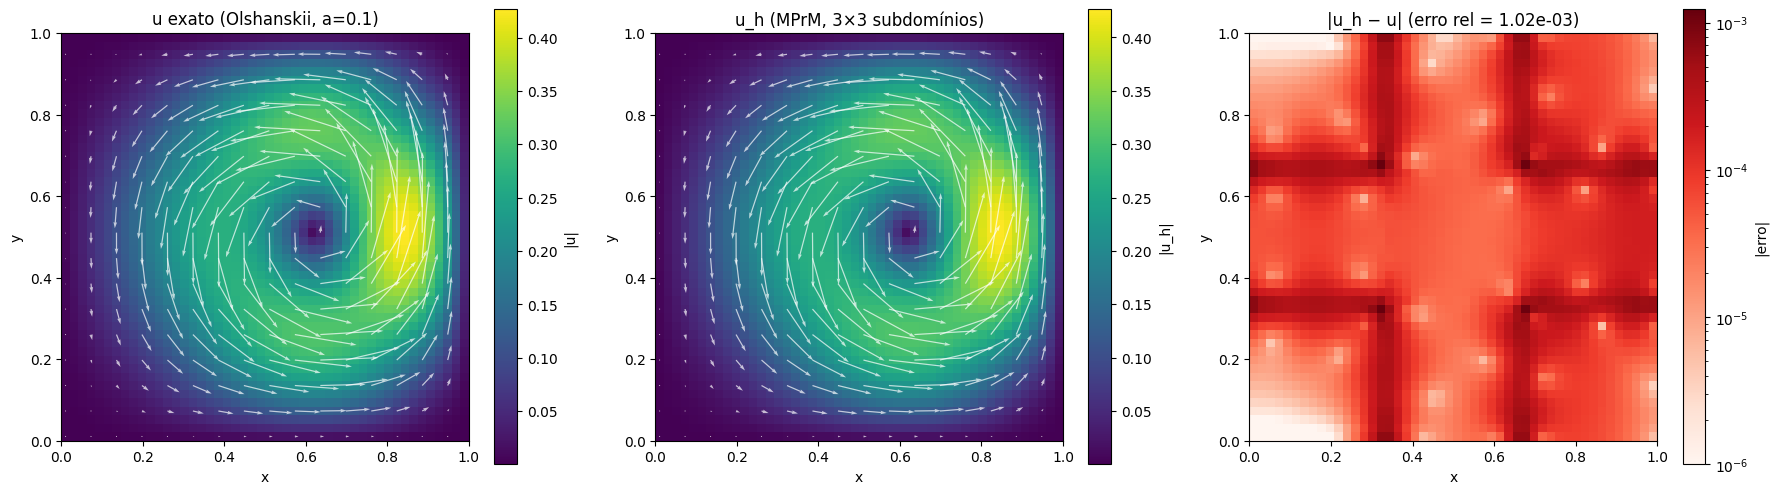

✓ Figura salva em hh_benchmark.png


In [21]:
# =============================================================================
# Célula 5 — Visualização do benchmark HH
# =============================================================================
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

if rank == 0:
    uh1, uh2 = result_hh["u"]
    ue1, ue2 = result_hh["u_exact"]
    N_hh = result_hh["N"]

    # Malha para plot
    x_faces = np.linspace(0, 1, N_hh + 1)
    y_faces = np.linspace(0, 1, N_hh + 1)
    x_cells = (x_faces[:-1] + x_faces[1:]) / 2
    y_cells = (y_faces[:-1] + y_faces[1:]) / 2

    # Velocidade nos centros das células para plot
    u_center = 0.5 * (uh1[:-1, :] + uh1[1:, :])
    v_center = 0.5 * (uh2[:, :-1] + uh2[:, 1:])
    ue_center = 0.5 * (ue1[:-1, :] + ue1[1:, :])
    ve_center = 0.5 * (ue2[:, :-1] + ue2[:, 1:])

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # Campo exato
    mag_exact = np.sqrt(ue_center**2 + ve_center**2)
    im0 = axes[0].pcolormesh(x_cells, y_cells, mag_exact.T, shading='auto', cmap='viridis')
    axes[0].quiver(x_cells[::3], y_cells[::3],
                   ue_center[::3, ::3].T, ve_center[::3, ::3].T,
                   scale=2, width=0.003, color='white', alpha=0.7)
    axes[0].set_title(f"u exato (Olshanskii, a={A_OLSH})")
    axes[0].set_xlabel("x"); axes[0].set_ylabel("y")
    axes[0].set_aspect('equal')
    plt.colorbar(im0, ax=axes[0], label='|u|')

    # Campo reconstruído
    mag_recon = np.sqrt(u_center**2 + v_center**2)
    im1 = axes[1].pcolormesh(x_cells, y_cells, mag_recon.T, shading='auto', cmap='viridis')
    axes[1].quiver(x_cells[::3], y_cells[::3],
                   u_center[::3, ::3].T, v_center[::3, ::3].T,
                   scale=2, width=0.003, color='white', alpha=0.7)
    axes[1].set_title(f"u_h (MPrM, {Ndom}×{Ndom} subdomínios)")
    axes[1].set_xlabel("x"); axes[1].set_ylabel("y")
    axes[1].set_aspect('equal')
    plt.colorbar(im1, ax=axes[1], label='|u_h|')

    # Erro
    err = np.sqrt((u_center - ue_center)**2 + (v_center - ve_center)**2)
    im2 = axes[2].pcolormesh(x_cells, y_cells, err.T, shading='auto',
                             cmap='Reds', norm=mcolors.LogNorm(vmin=1e-6, vmax=err.max()))
    axes[2].set_title(f"|u_h − u| (erro rel = {result_hh['err_u']:.2e})")
    axes[2].set_xlabel("x"); axes[2].set_ylabel("y")
    axes[2].set_aspect('equal')
    plt.colorbar(im2, ax=axes[2], label='|erro|')

    plt.tight_layout()
    plt.savefig("hh_benchmark.png", dpi=150, bbox_inches='tight')
    plt.show()
    print("✓ Figura salva em hh_benchmark.png")


## 5. Benchmark 2 — Cavidade com Tampa Deslizante (Lid-Driven Cavity)

### Descrição (Lages, §3.3; Ghia et al., 1982)

O escoamento em uma cavidade quadrada $[0,1]^2$ com tampa móvel é um benchmark
clássico da dinâmica dos fluidos computacional:

- **Paredes**: estacionárias ($\mathbf{u}=0$) em $x=0$, $x=1$, $y=0$
- **Tampa**: velocidade tangencial $U_{\text{lid}} = 1$ em $y=1$
- **Condição de contorno**: não-deslizamento ($\mathbf{u}\cdot\mathbf{n}=0$
  e $\mathbf{u}\cdot\boldsymbol{\tau}=U_{\text{parede}}$)

O fluido parte do repouso ($\mathbf{u}=0$) e evolui até $t = T$.

### Métricas de comparação

- **Perfis de velocidade** nas linhas centrais $x=0.5$ e $y=0.5$, comparados
  com a referência de Ghia et al. (1982) para o estado estacionário.
- **Linhas de corrente** e campo de vorticidade no regime estabelecido.
- **Divergência máxima** $\max|\nabla\cdot\mathbf{u}|$ (ideal: 0).
- **Comparação MPrM × malha fina** (sem decomposição de domínio).

### Resultado esperado

Para $Re=100$, espera-se a formação do vórtice primário centrado em
$(x,y) \approx (0.62, 0.74)$ e vórtices secundários nos cantos inferiores
(Ghia et al., 1982). O MPrM deve reproduzir qualitativamente estes padrões,
com erro controlado pela decomposição de domínio.


In [22]:
# =============================================================================
# Célula 6 — Execução da cavidade (MPrM)
# =============================================================================
if rank == 0:
    print("=" * 60)
    print("Benchmark 2: Cavidade com Tampa Deslizante (MPrM)")
    print(f"Re = {Re}, N = {N}×{N}, subdomínios = {Ndom}×{Ndom}")
    print("=" * 60)

t0 = time.perf_counter()

result_mprm = run_cavity(
    Re=Re, Ndom=Ndom, nloc=nloc, T=T, dt=dt,
    lid_velocity=lid_velocity,
    degreeU=degreeU, degreeP=degreeP, alpha=alpha,
    method="mprm", comm=comm, verbose=True, log_every=max(1, nsteps // 10),
)

t_wall_mprm = time.perf_counter() - t0

if rank == 0:
    print(f"\n--- Resultados MPrM (N={result_mprm['N']}) ---")
    print(f"  Tempo de parede:        {t_wall_mprm:.2f} s")
    print(f"  Passos:                 {result_mprm['nsteps']}")
    print(f"  Tempo/passo:            {t_wall_mprm/result_mprm['nsteps']:.4f} s")
    print(f"  max|div u|:              {result_mprm['divmax']:.6e}")
    print(f"  Defeito downscaling:     {result_mprm['defect']:.6e}")


Benchmark 2: Cavidade com Tampa Deslizante (MPrM)
Re = 100.0, N = 48×48, subdomínios = 3×3


/home/callebez/venv-firedrake/lib/python3.12/site-packages/scikits/umfpack/umfpack.py:737: UmfpackWarning: (almost) singular matrix! (estimated cond. number: 3.71e+12)
  warnings.warn(msg, UmfpackWarning)


  passo 184/1844  t=0.799  max|div u| = 6.49e-15
  passo 368/1844  t=1.597  max|div u| = 7.33e-15
  passo 552/1844  t=2.396  max|div u| = 7.11e-15
  passo 736/1844  t=3.194  max|div u| = 6.44e-15
  passo 920/1844  t=3.993  max|div u| = 7.55e-15
  passo 1104/1844  t=4.792  max|div u| = 6.41e-15
  passo 1288/1844  t=5.590  max|div u| = 6.66e-15
  passo 1472/1844  t=6.389  max|div u| = 7.99e-15
  passo 1656/1844  t=7.188  max|div u| = 6.00e-15
  passo 1840/1844  t=7.986  max|div u| = 7.99e-15

--- Resultados MPrM (N=48) ---
  Tempo de parede:        131.42 s
  Passos:                 1844
  Tempo/passo:            0.0713 s
  max|div u|:              5.828671e-15
  Defeito downscaling:     3.575265e-15


### 5.1 Referência de Malha Fina (sem decomposição de domínio)

Para avaliar a acurácia do MPrM, executamos o mesmo problema com o solver de
malha fina (projeção de Chorin sem decomposição de domínio, mesma malha MAC).
Este é o "*fine mesh solver*" mencionado no artigo (§2.7).

**Nota:** Esta célula pode ser demorada para malhas grandes. Ajuste `nloc`
para testes rápidos.


In [23]:
# =============================================================================
# Célula 7 — Referência de malha fina (opcional — pode ser lenta)
# =============================================================================
RUN_FINE_REFERENCE = True  # Altere para False para pular

if RUN_FINE_REFERENCE and rank == 0:
    print("=" * 60)
    print("Referência: Malha Fina (sem decomposição)")
    print(f"Re = {Re}, N = {N}×{N}")
    print("=" * 60)

    t0 = time.perf_counter()
    result_fine = run_cavity(
        Re=Re, Ndom=Ndom, nloc=nloc, T=T, dt=dt,
        lid_velocity=lid_velocity,
        method="fine", comm=comm, verbose=True, log_every=max(1, nsteps // 10),
    )
    t_wall_fine = time.perf_counter() - t0

    print(f"\n--- Resultados Malha Fina (N={result_fine['N']}) ---")
    print(f"  Tempo de parede:    {t_wall_fine:.2f} s")
    print(f"  Tempo/passo:        {t_wall_fine/result_fine['nsteps']:.4f} s")
    print(f"  max|div u|:          {result_fine['divmax']:.6e}")

    # Erro relativo MPrM × Fino
    u_mprm, v_mprm = result_mprm["u"], result_mprm["v"]
    u_fine, v_fine = result_fine["u"], result_fine["v"]
    err_u = np.sqrt(np.sum((u_mprm - u_fine)**2) + np.sum((v_mprm - v_fine)**2))
    den_u = np.sqrt(np.sum(u_fine**2) + np.sum(v_fine**2))
    print(f"\n  Erro relativo MPrM × Fino: {err_u/den_u:.6e}")
    print(f"  Speedup (MPrM/Fino):       {t_wall_fine/t_wall_mprm:.2f}×"
          f"  (NÃO é speedup paralelo — apenas parede sequencial)")
elif not RUN_FINE_REFERENCE:
    if rank == 0:
        print("⏭ Referência fina pulada (RUN_FINE_REFERENCE = False)")


Referência: Malha Fina (sem decomposição)
Re = 100.0, N = 48×48
  passo 184/1844  t=0.799  max|div u| = 8.22e-15
  passo 368/1844  t=1.597  max|div u| = 2.62e-14
  passo 552/1844  t=2.396  max|div u| = 3.97e-14
  passo 736/1844  t=3.194  max|div u| = 4.60e-14
  passo 920/1844  t=3.993  max|div u| = 5.00e-14
  passo 1104/1844  t=4.792  max|div u| = 5.95e-14
  passo 1288/1844  t=5.590  max|div u| = 5.41e-14
  passo 1472/1844  t=6.389  max|div u| = 6.24e-14
  passo 1656/1844  t=7.188  max|div u| = 6.08e-14
  passo 1840/1844  t=7.986  max|div u| = 6.53e-14

--- Resultados Malha Fina (N=48) ---
  Tempo de parede:    1.44 s
  Tempo/passo:        0.0008 s
  max|div u|:          6.199034e-14

  Erro relativo MPrM × Fino: 5.318490e-04
  Speedup (MPrM/Fino):       0.01×  (NÃO é speedup paralelo — apenas parede sequencial)


## 6. Visualização e Análise dos Resultados

### 6.1 Campo de Velocidade e Linhas de Corrente

O campo de velocidades da cavidade no regime estabelecido ($t = T$) exibe a
estrutura clássica de vórtice primário. As linhas de corrente são calculadas
a partir da função corrente $\psi$ ($u = \partial\psi/\partial y$,
$v = -\partial\psi/\partial x$).


In [24]:
# =============================================================================
# Célula 8 — Visualização: Campo de velocidade e linhas de corrente
# =============================================================================
if rank == 0:
    u, v = result_mprm["u"], result_mprm["v"]
    N_viz = result_mprm["N"]

    # Malha para visualização
    xf = np.linspace(0, 1, N_viz + 1)
    yf = np.linspace(0, 1, N_viz + 1)
    xc = (xf[:-1] + xf[1:]) / 2
    yc = (yf[:-1] + yf[1:]) / 2

    # Velocidade nos centros
    uc = 0.5 * (u[:-1, :] + u[1:, :])
    vc = 0.5 * (v[:, :-1] + v[:, 1:])
    mag = np.sqrt(uc**2 + vc**2)

    # Função corrente: ψ = ∫ u dy, com ψ=0 no contorno inferior
    psi = np.zeros((N_viz + 1, N_viz + 1))
    for i in range(N_viz):
        psi[i + 1, :] = psi[i, :] - 0.5 * (vc[i, :] + vc[i + 1, :]) * (1.0 / N_viz)

    fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

    # Magnitude da velocidade
    im0 = axes[0].pcolormesh(xc, yc, mag.T, shading='auto', cmap='turbo')
    axes[0].quiver(xc[::2], yc[::2],
                   uc[::2, ::2].T, vc[::2, ::2].T,
                   scale=3, width=0.003, color='white', alpha=0.6)
    axes[0].set_title(f"|u| — MPrM, Re={Re}, t={T}")
    axes[0].set_xlabel("x"); axes[0].set_ylabel("y")
    axes[0].set_aspect('equal')
    plt.colorbar(im0, ax=axes[0], label='|u|')

    # Linhas de corrente
    im1 = axes[1].contourf(xc, yc, psi.T, levels=30, cmap='Blues')
    axes[1].contour(xc, yc, psi.T, levels=30, colors='k', linewidths=0.3)
    axes[1].set_title(f"Função corrente ψ — MPrM, Re={Re}")
    axes[1].set_xlabel("x"); axes[1].set_ylabel("y")
    axes[1].set_aspect('equal')
    plt.colorbar(im1, ax=axes[1], label='ψ')

    # Divergência
    div = mac_divergence(u, v, 1.0/N_viz, 1.0/N_viz)
    im2 = axes[2].pcolormesh(xc, yc, div.T, shading='auto',
                             cmap='RdBu_r',
                             norm=mcolors.SymLogNorm(linthresh=1e-14, vmin=-1e-12, vmax=1e-12))
    axes[2].set_title(f"∇·u (max = {result_mprm['divmax']:.2e})")
    axes[2].set_xlabel("x"); axes[2].set_ylabel("y")
    axes[2].set_aspect('equal')
    plt.colorbar(im2, ax=axes[2], label='∇·u')

    plt.tight_layout()
    plt.savefig("cavity_fields.png", dpi=150, bbox_inches='tight')
    plt.show()
    print("✓ Figura salva em cavity_fields.png")


ValueError: operands could not be broadcast together with shapes (49,) (48,) 

### 6.2 Perfis de Velocidade nas Linhas Centrais

Comparamos os perfis de velocidade $u(x=0.5, y)$ e $v(x, y=0.5)$ com os
resultados de referência de Ghia et al. (1982). Estes perfis são a assinatura
do escoamento em cavidade e permitem validação quantitativa.

**Nota:** Os dados de Ghia et al. para Re=100 são incluídos como referência
visual. Para uma validação rigorosa, seria necessário interpolar na mesma malha.


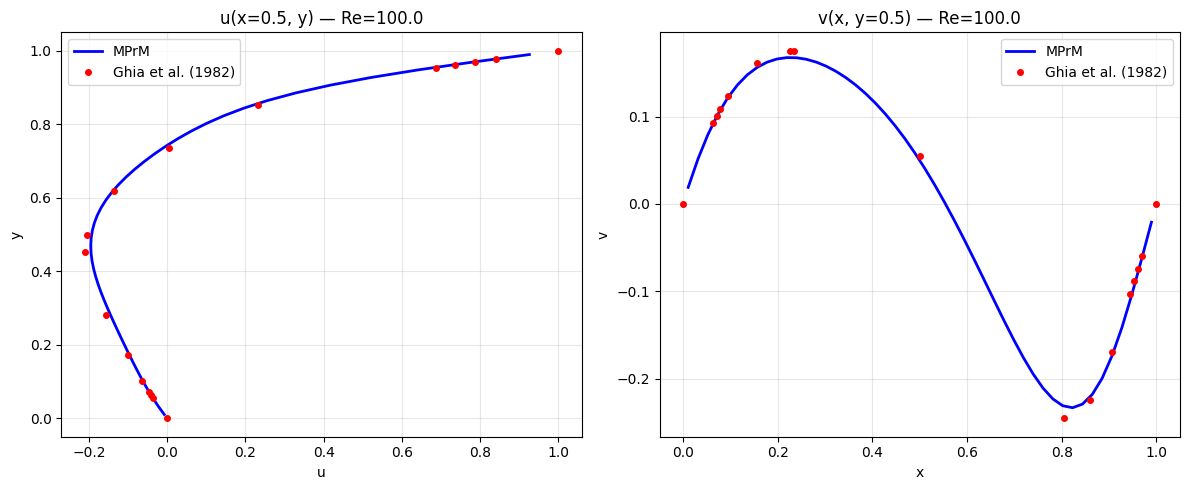

✓ Figura salva em cavity_profiles.png


In [25]:
# =============================================================================
# Célula 9 — Perfis de velocidade nas linhas centrais
# =============================================================================
if rank == 0:
    u, v = result_mprm["u"], result_mprm["v"]
    N_viz = result_mprm["N"]
    xf = np.linspace(0, 1, N_viz + 1)
    yc = (np.arange(N_viz) + 0.5) / N_viz
    xc = (np.arange(N_viz) + 0.5) / N_viz
    yf = np.linspace(0, 1, N_viz + 1)

    # Perfil u na linha central vertical (x = 0.5)
    ix_mid = N_viz // 2
    u_mid = u[ix_mid, :]

    # Perfil v na linha central horizontal (y = 0.5)
    iy_mid = N_viz // 2
    v_mid = v[:, iy_mid]

    # Dados de Ghia et al. (1982) para Re = 100
    # (amostragem representativa — valores aproximados do artigo original)
    ghia_y = np.array([0.0, 0.0547, 0.0625, 0.0703, 0.1016, 0.1719, 0.2813,
                       0.4531, 0.5, 0.6172, 0.7344, 0.8516, 0.9531, 0.9609,
                       0.9688, 0.9766, 1.0])
    ghia_u = np.array([0.0, -0.03717, -0.04192, -0.04775, -0.06434, -0.10150,
                       -0.15662, -0.21090, -0.20581, -0.13641, 0.00332, 0.23151,
                       0.68717, 0.73722, 0.78871, 0.84123, 1.0])

    ghia_x = np.array([0.0, 0.0625, 0.0703, 0.0781, 0.0938, 0.1563, 0.2266,
                       0.2344, 0.5, 0.8047, 0.8594, 0.9063, 0.9453, 0.9531,
                       0.9609, 0.9688, 1.0])
    ghia_v = np.array([0.0, 0.09233, 0.10091, 0.10890, 0.12317, 0.16077,
                       0.17507, 0.17527, 0.05454, -0.24533, -0.22445, -0.16914,
                       -0.10313, -0.08864, -0.07391, -0.05906, 0.0])

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

    ax1.plot(u_mid, yc, 'b-', linewidth=2, label='MPrM')
    ax1.plot(ghia_u, ghia_y, 'ro', markersize=4, label='Ghia et al. (1982)')
    ax1.set_xlabel('u')
    ax1.set_ylabel('y')
    ax1.set_title(f'u(x=0.5, y) — Re={Re}')
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    ax2.plot(xc, v_mid, 'b-', linewidth=2, label='MPrM')
    ax2.plot(ghia_x, ghia_v, 'ro', markersize=4, label='Ghia et al. (1982)')
    ax2.set_xlabel('x')
    ax2.set_ylabel('v')
    ax2.set_title(f'v(x, y=0.5) — Re={Re}')
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig("cavity_profiles.png", dpi=150, bbox_inches='tight')
    plt.show()
    print("✓ Figura salva em cavity_profiles.png")


## 7. Execução Paralela com MPI

O MPrM é **naturalmente paralelo** (Lages, §2.8; Jaramillo et al., 2022):

- **Fase offline (MsBF):** cada subdomínio é independente — zero comunicação.
- **Fase online (particular + downscaling):** idem, independente por subdomínio.
- **Sistema de interface:** resolvido no rank 0 (gargalo de Amdahl,
  tipicamente < 15% do tempo total).

### Modos de execução suportados

| Modo | Comando | Uso |
|------|---------|-----|
| Sequencial | Executar no notebook | Debug e desenvolvimento |
| MPI | `mpiexec -n N python script.py` | Produção, HPC |

### Como executar com MPI

O notebook atual roda em modo sequencial. Para execução paralela, use o script
abaixo (salvo como `run_mprm_mpi.py`) com `mpiexec`:

```bash
mpiexec -n 4 python run_mprm_mpi.py
```

O `mprm_core.py` já implementa a distribuição round-robin de subdomínios entre
ranks e a coleta de resultados via `comm.allgather()`. Com `comm` de tamanho 1,
o código degenera naturalmente para o caminho sequencial.

### Estimativa de custo (Lages, Eqs. 34–36)

Para $N$ subdomínios, $k_U + k_P$ DOFs por interface, e custo $C_{BF}$ por
MsBF:

$$\text{custo}_{\text{offline}}^{\text{paralelo}} = 4(k_U + k_P)\,C_{BF}$$
$$\text{custo}_{\text{online}}^{\text{paralelo}} = 2\,C_{BF} + C_I$$

O *sweet spot* ocorre quando o custo de resolver o sistema de interface
($C_I$) equilibra o custo dos problemas locais. Para o caso com
$360 \times 360$ células, o ótimo teórico está em $12 \times 12$ subdomínios
(redução de 94–98% no custo, Lages, Fig. 3).


In [26]:
# =============================================================================
# Célula 10 — Script para execução MPI standalone
# =============================================================================
# Esta célula gera um script Python que pode ser executado com mpiexec.
# O script roda a cavidade com MPrM usando múltiplos ranks MPI.

MPI_SCRIPT = """#!/usr/bin/env python3
\"\"\"run_mprm_mpi.py — Cavidade MPrM com MPI.\"\"\"
import sys, os
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
sys.path.insert(0, os.path.expanduser("~/mrcm/mrcm-firedrake"))

from mpi4py import MPI
from mprm_core import run_cavity

comm = MPI.COMM_WORLD
rank, size = comm.rank, comm.size

result = run_cavity(
    Re={Re}, Ndom={Ndom}, nloc={nloc}, T={T}, dt={dt},
    lid_velocity={lid_velocity},
    degreeU={degreeU}, degreeP={degreeP}, alpha={alpha},
    method="mprm", comm=comm, verbose=(rank == 0),
    log_every=max(1, {nsteps} // 10),
)

if rank == 0:
    print(f"\\nMPI com {{size}} ranks:")
    print(f"  Tempo: {{result['t_wall']:.2f}} s")
    print(f"  max|div u|: {{result['divmax']:.6e}}")
    print(f"  Defeito: {{result['defect']:.6e}}")
""".format(Re=Re, Ndom=Ndom, nloc=nloc, T=T, dt=dt,
           lid_velocity=lid_velocity, degreeU=degreeU, degreeP=degreeP,
           alpha=alpha, nsteps=nsteps)

with open("run_mprm_mpi.py", "w") as f:
    f.write(MPI_SCRIPT)

if rank == 0:
    print("✓ Script MPI gerado: run_mprm_mpi.py")
    print(f"\nPara executar com 4 processos MPI:")
    print(f"  mpiexec -n 4 python run_mprm_mpi.py")
    print(f"\n(Execute no terminal, não no notebook)")


✓ Script MPI gerado: run_mprm_mpi.py

Para executar com 4 processos MPI:
  mpiexec -n 4 python run_mprm_mpi.py

(Execute no terminal, não no notebook)


## 7.5 Animação da Evolução Temporal (GIF/MP4)

O MPrM pode gerar uma animação da evolução do campo de velocidades ao longo do
tempo. O procedimento é:

1. Executar a simulação com um **callback de frame** que salva imagens PNG a
   cada $N$ passos de tempo.
2. Combinar os frames em um **GIF animado** usando `imageio` ou `Pillow`.

As funções `make_frame_saver()` e `make_gif()` em `mprm_core.py` implementam
esta funcionalidade.

**Nota:** Gere frames com resolução moderada (`nloc=10`, `Ndom=2`, poucos passos)
para testes rápidos. Para um vídeo de alta qualidade, aumente a resolução e
use mais frames.


In [ ]:
# =============================================================================
# Célula 10b — Gerar frames da evolução temporal
# =============================================================================
# Parâmetros para animação (use resolução baixa para teste rápido)
ANIM_Ndom = 3              # subdomínios
ANIM_nloc = 12             # células por subdomínio (48×48 global)
ANIM_Re = 100.0
ANIM_T = 6.0               # tempo final (menor que o benchmark)
ANIM_frame_every = 15      # salvar a cada N passos
ANIM_output_dir = "frames_mprm"

if rank == 0:
    print("=" * 60)
    print("Gerando frames para animação...")
    print(f"Re={ANIM_Re}, malha={(ANIM_Ndom*ANIM_nloc)}², T={ANIM_T}")
    print(f"Salvando a cada {ANIM_frame_every} passos em '{ANIM_output_dir}/'")
    print("=" * 60)

    # Instalar imageio se necessário
    try:
        import imageio
    except ImportError:
        import subprocess, sys
        subprocess.check_call([sys.executable, "-m", "pip", "install", "imageio"])
        import imageio
    print("✓ imageio disponível")

# Cria o callback que salva frames
saver = make_frame_saver(
    output_dir=ANIM_output_dir,
    dpi=100,
    Re=ANIM_Re,
    title_prefix="MPrM",
)

# Executa a simulação com callback de frames
result_anim = run_cavity(
    Re=ANIM_Re, Ndom=ANIM_Ndom, nloc=ANIM_nloc, T=ANIM_T,
    lid_velocity=1.0,
    degreeU=degreeU, degreeP=degreeP, alpha=alpha,
    method="mprm", comm=comm, verbose=True,
    log_every=50,
    frame_callback=saver,
    frame_every=ANIM_frame_every,
)

if rank == 0:
    import glob
    nframes = len(glob.glob(f"{ANIM_output_dir}/frame_*.png"))
    print(f"\n✓ {nframes} frames salvos em '{ANIM_output_dir}/'")
    print(f"  Tempo total: {result_anim['t_wall']:.2f} s")
    print(f"  max|div u|:  {result_anim['divmax']:.2e}")


In [ ]:
# =============================================================================
# Célula 10c — Criar GIF animado a partir dos frames
# =============================================================================
if rank == 0:
    gif_path = make_gif(
        frame_dir=ANIM_output_dir,
        output="cavity_mprm.gif",
        fps=10,
    )
    print(f"✓ GIF criado: {gif_path}")

    # Exibe o GIF no notebook
    from IPython.display import Image as IPImage, display
    display(IPImage(filename=gif_path))


## 8. Referências

1. **Lages, C.** — *The multiscale projection method for the solution of
   incompressible Navier-Stokes equations.* Artigo principal do MPrM.

2. **Guiraldello, R.T., Ausas, R.F., Sousa, F.S., Pereira, F., Buscaglia,
   G.C. (2018).** *The Multiscale Robin Coupled Method for flows in porous
   media.* Journal of Computational Physics, 355:1–21.
   DOI: [10.1016/j.jcp.2017.11.004](https://doi.org/10.1016/j.jcp.2017.11.004)

3. **Guiraldello, R.T. et al. (2019).** *The multiscale Robin coupled method
   for flows in porous media: analysis of the interface spaces and Robin
   parameter.* (Análise dos espaços de interface e recomendação $k_U$, $k_P$)

4. **Chorin, A.J. (1968).** *Numerical solution of the Navier-Stokes
   equations.* Mathematics of Computation, 22:745–762.
   DOI: [10.1090/S0025-5718-1968-0242392-2](https://doi.org/10.1090/S0025-5718-1968-0242392-2)

5. **Ghia, U., Ghia, K.N., Shin, C.T. (1982).** *High-Re solutions for
   incompressible flow using the Navier-Stokes equations and a multigrid
   method.* Journal of Computational Physics, 48:387–411.

6. **Jaramillo, A. et al. (2022).** *Towards HPC simulations of billion-cell
   reservoirs by multiscale mixed methods.* (Paralelização MPI do MRCM,
   escalabilidade até bilhões de células)

7. **Rocha, F. et al. (2020).** *Multiscale mixed methods with improved
   accuracy: The role of oversampling.* (MRCM adaptativo, $\alpha(x)$)

8. **Araya, R., Barrenechea, G.R., Valentin, F. (2006).** *Stabilized finite
   element methods based on multiscale enrichment for the Stokes problem.*
   SIAM J. Numer. Anal., 44(1):322–348.

9. **Baiges, J., Codina, R., Idelsohn, S. (2013).** *A domain decomposition
   strategy for reduced order models. Application to the incompressible
   Navier–Stokes equations.* Comput. Methods Appl. Mech. Engrg., 267:23–42.

10. **Abdulle, A., Budáč, O. (2015).** *An adaptive finite element
    heterogeneous multiscale method for Stokes flow in porous media.*
    SIAM Multiscale Model. Simul., 13(1):256–290.

---

## 9. Resumo e Conclusões

### O que foi implementado

- ✅ Método de projeção de Chorin não-incremental (Eqs. 8–10)
- ✅ Transporte explícito na malha MAC (FV staggered, upwind + diferenças centrais)
- ✅ Projeção MRCM com estrutura offline/online (Algoritmo 1)
- ✅ Downscaling com média de fluxos + problemas de Neumann locais (Eqs. 21–23)
- ✅ Benchmark de Helmholtz-Hodge (Olshanskii, validação da decomposição)
- ✅ Benchmark de cavidade (lid-driven cavity, Re configurável)
- ✅ Suporte a paralelismo MPI (subdomínios distribuídos entre ranks)

### Observações importantes

1. **Desvio de discretização:** O transporte usa malha MAC (FV staggered) enquanto o
   MRCM usa elementos finitos BDM₁–DG₀ em triângulos (Firedrake). Esta diferença é
   conhecida e documentada — ambos são equivalentes de ordem mais baixa.

2. **Sinal da projeção:** O MRCM usa a convenção de Darcy $\mathbf{u}_D = -K\nabla p_D$;
   o MPrM precisa de $\mathbf{v} = +\delta t\,\nabla p$. Com $K=\delta t$ e fonte
   $\nabla\cdot\mathbf{w}^*$, a pressão resolvida pelo MRCM é $p_D = -p$ e portanto a
   velocidade reconstruída já é $\mathbf{v} = +\delta t\,\nabla p$ — **nenhuma correção
   de sinal é aplicada (nem necessária)** no pipeline; apenas a pressão do MRCM
   (`last_pT`) tem o sinal trocado em relação à pressão física (relevante só para
   visualização).

3. **Custo offline × online:** Para simulações longas ($n_{\text{steps}} \gg 1$),
   o custo offline (MsBF + fatorações) é amortizado. O custo online é dominado
   pelos problemas locais independentes (70–90% do tempo) e pelo sistema de
   interface (5–15%).

4. **Paralelismo:** O MPrM é embaraçosamente paralelo nas fases locais. O gargalo
   de Amdahl é o sistema global de interface (resolvido no rank 0). Para muitas
   interfaces, recomenda-se usar o solver iterativo (GMRES + ILU) do `mrcm`
   (`global_solver="iterative"`).
